<a href="https://colab.research.google.com/github/Fa-224/Image-Processing-Project/blob/main/Planty_Final_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Disease Classification Using CNN
## Evaluating the Effect of Image Filtering Techniques
This project investigates the effect of different image filtering techniques on plant disease classification using a Convolutional Neural Network (CNN).
Four experiments are conducted:
1. Original RGB Images (Baseline)
2. Gaussian Smoothing
3. Sharpening
4. Gaussian Smoothing followed by Sharpening


## 1. Import Libraries

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from PIL import Image
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)


TensorFlow version: 2.21.0
OpenCV version: 4.14.0


## 2. Download and Inspect the Dataset

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset directory: /kaggle/input/plantdisease/PlantVillage
Number of classes: 15


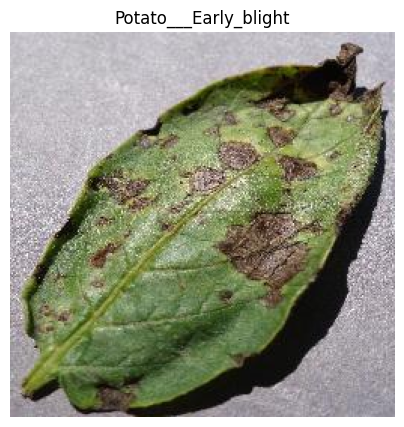

Image size: (256, 256)
Color mode: RGB


In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("emmarex/plantdisease")
data_dir = os.path.join(dataset_path, "PlantVillage")

print("Dataset directory:", data_dir)
print("Number of classes:", len([
    name for name in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, name))
]))

# Display one sample image
sample_class = "Potato___Early_blight"
sample_class_dir = os.path.join(data_dir, sample_class)

sample_name = next(
    name for name in os.listdir(sample_class_dir)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
)
sample_path = os.path.join(sample_class_dir, sample_name)

sample_image = Image.open(sample_path).convert("RGB")
plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title(sample_class)
plt.axis("off")
plt.show()

print("Image size:", sample_image.size)
print("Color mode:", sample_image.mode)


## 3. RGB to HSV (Exploratory Visualization)

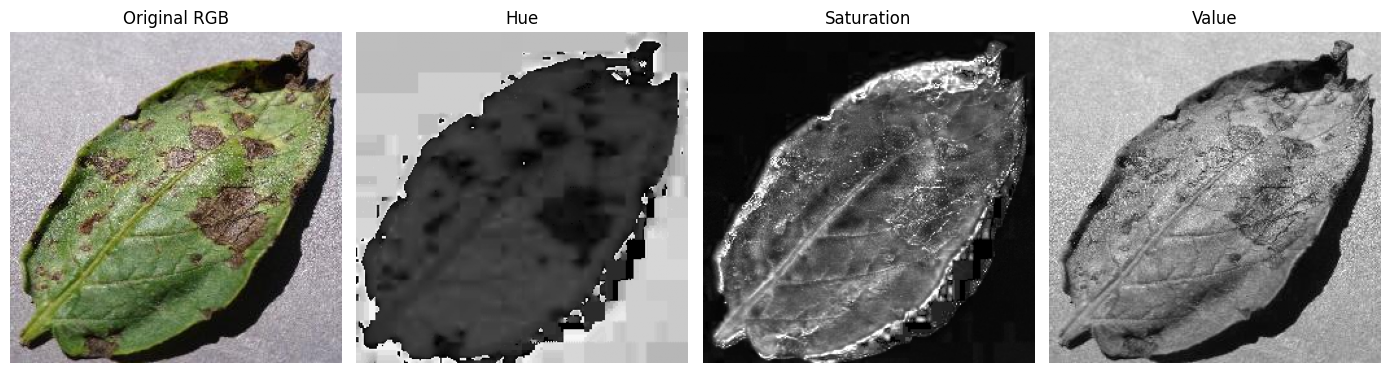

In [4]:
from skimage.color import rgb2hsv

sample_array = np.asarray(sample_image).astype("float32") / 255.0
hsv_image = rgb2hsv(sample_array)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(sample_array)
axes[0].set_title("Original RGB")
axes[1].imshow(hsv_image[:, :, 0], cmap="gray")
axes[1].set_title("Hue")
axes[2].imshow(hsv_image[:, :, 1], cmap="gray")
axes[2].set_title("Saturation")
axes[3].imshow(hsv_image[:, :, 2], cmap="gray")
axes[3].set_title("Value")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# RGB remains the model input. HSV is shown here for exploration only.


## 4. Collect and Validate Image Paths

In [5]:
image_paths = []
labels = []

valid_extensions = (".jpg", ".jpeg", ".png")

for class_name in sorted(os.listdir(data_dir)):
    class_dir = os.path.join(data_dir, class_name)
    if not os.path.isdir(class_dir):
        continue

    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(valid_extensions):
            file_path = os.path.join(class_dir, filename)
            try:
                with Image.open(file_path) as img:
                    img.verify()
                image_paths.append(file_path)
                labels.append(class_name)
            except Exception:
                print("Skipped invalid image:", file_path)

print("Total valid images:", len(image_paths))
print("Number of classes:", len(set(labels)))
print("Images per class:")
print(Counter(labels))


Total valid images: 20638
Number of classes: 15
Images per class:
Counter({'Tomato__Tomato_YellowLeaf__Curl_Virus': 3208, 'Tomato_Bacterial_spot': 2127, 'Tomato_Late_blight': 1909, 'Tomato_Septoria_leaf_spot': 1771, 'Tomato_Spider_mites_Two_spotted_spider_mite': 1676, 'Tomato_healthy': 1591, 'Pepper__bell___healthy': 1478, 'Tomato__Target_Spot': 1404, 'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Tomato_Early_blight': 1000, 'Pepper__bell___Bacterial_spot': 997, 'Tomato_Leaf_Mold': 952, 'Tomato__Tomato_mosaic_virus': 373, 'Potato___healthy': 152})


## 5. Split the Dataset (70% / 15% / 15%)

In [6]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

# Create a consistent label-to-index mapping
class_names = sorted(set(labels))
class_to_idx = {name: index for index, name in enumerate(class_names)}
idx_to_class = {index: name for name, index in class_to_idx.items()}
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)


Training images: 14446
Validation images: 3096
Testing images: 3096
Number of classes: 15


## 6. Configure Image Size and Filtering Functions

In [7]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5

# Sharpening kernel used in the filtering experiment
SHARPEN_KERNEL = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

def apply_filter_numpy(image, filter_name):
    # image is a float32 RGB image with values approximately in [0, 255]
    image = np.clip(image, 0, 255).astype(np.uint8)

    if filter_name == "original":
        result = image
    elif filter_name == "gaussian":
        result = cv2.GaussianBlur(image, (5, 5), 0)
    elif filter_name == "sharpen":
        result = cv2.filter2D(image, -1, SHARPEN_KERNEL)
    elif filter_name == "gaussian_sharpen":
        smoothed = cv2.GaussianBlur(image, (5, 5), 0)
        result = cv2.filter2D(smoothed, -1, SHARPEN_KERNEL)
    else:
        raise ValueError("Unknown filter: " + filter_name)

    return result.astype(np.float32)

print("Available experiments: original, gaussian, sharpen, gaussian_sharpen")


Available experiments: original, gaussian, sharpen, gaussian_sharpen


## 7. Visualize the Filtering Results

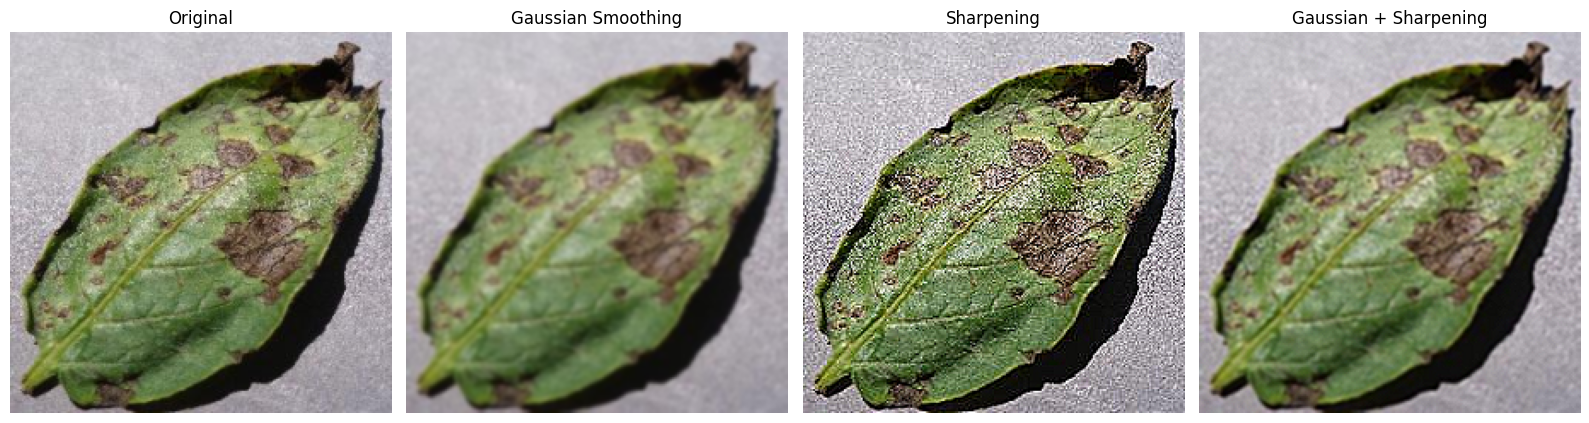

In [8]:
# Display the same sample with each filtering option
sample_resized = cv2.resize(
    np.asarray(sample_image),
    IMG_SIZE,
    interpolation=cv2.INTER_AREA
)

filter_names = ["original", "gaussian", "sharpen", "gaussian_sharpen"]
filter_titles = [
    "Original",
    "Gaussian Smoothing",
    "Sharpening",
    "Gaussian + Sharpening"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, filter_name, title in zip(axes, filter_names, filter_titles):
    filtered = apply_filter_numpy(sample_resized, filter_name)
    ax.imshow(np.clip(filtered, 0, 255).astype(np.uint8))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 8. Create TensorFlow Datasets with the Selected Filter

In [9]:
def load_image(path, label, filter_name):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Resize first, then apply the selected image filter
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.numpy_function(
        func=lambda img: apply_filter_numpy(img, filter_name),
        inp=[image],
        Tout=tf.float32
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])

    # Normalize pixel values to [0, 1]
    image = tf.clip_by_value(image, 0.0, 255.0) / 255.0
    return image, label


def create_dataset(paths, label_names, filter_name, shuffle=False):
    numeric_labels = [class_to_idx[name] for name in label_names]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numeric_labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=min(len(paths), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label: load_image(path, label, filter_name),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


def make_experiment_datasets(filter_name):
    train_ds = create_dataset(
        train_paths, train_labels, filter_name, shuffle=True
    )
    val_ds = create_dataset(
        val_paths, val_labels, filter_name, shuffle=False
    )
    test_ds = create_dataset(
        test_paths, test_labels, filter_name, shuffle=False
    )
    return train_ds, val_ds, test_ds

# Verify one batch
train_dataset, val_dataset, test_dataset = make_experiment_datasets("original")

for images_batch, labels_batch in train_dataset.take(1):
    print("Image batch shape:", images_batch.shape)
    print("Label batch shape:", labels_batch.shape)
    print("Pixel minimum:", float(tf.reduce_min(images_batch)))
    print("Pixel maximum:", float(tf.reduce_max(images_batch)))


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 0.9882352948188782


## 9. Build the CNN Model

In [10]:
def build_cnn_model():
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1)
    ], name="data_augmentation")

    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
        data_augmentation,

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Display the CNN architecture
model_summary = build_cnn_model()
model_summary.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,895 (42.61 MB)

 Trainable params: 11,170,895 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## 10. Train and Compare All Experiments

In [11]:
# Four independent experiments:
# 1) Original images (baseline)
# 2) Gaussian smoothing
# 3) Sharpening
# 4) Gaussian smoothing followed by sharpening

EXPERIMENTS = {
    "Original": "original",
    "Gaussian": "gaussian",
    "Sharpening": "sharpen",
    "Gaussian + Sharpening": "gaussian_sharpen"
}

trained_models = {}
histories = {}
results = []

for experiment_name, filter_name in EXPERIMENTS.items():
    print("\n" + "=" * 70)
    print("Starting experiment:", experiment_name)
    print("=" * 70)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    train_ds, val_ds, test_ds = make_experiment_datasets(filter_name)
    current_model = build_cnn_model()

    history = current_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS
    )

    test_loss, test_accuracy = current_model.evaluate(
        test_ds,
        verbose=1
    )

    trained_models[experiment_name] = current_model
    histories[experiment_name] = history

    results.append({
        "Experiment": experiment_name,
        "Best Validation Accuracy": max(history.history["val_accuracy"]),
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    })

    current_model.save(
        "plant_disease_" + filter_name + ".keras"
    )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nExperiment comparison:")
display(results_df)



Starting experiment: Original
Epoch 1/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 41s 77ms/step - accuracy: 0.3697 - loss: 1.9861 - val_accuracy: 0.5245 - val_loss: 1.4487
Epoch 2/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 37s 82ms/step - accuracy: 0.5646 - loss: 1.3406 - val_accuracy: 0.5972 - val_loss: 1.1605
Epoch 3/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - accuracy: 0.6329 - loss: 1.0994 - val_accuracy: 0.7057 - val_loss: 0.8475
Epoch 4/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.6876 - loss: 0.9302 - val_accuracy: 0.7112 - val_loss: 0.8293
Epoch 5/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 45s 82ms/step - accuracy: 0.7053 - loss: 0.8703 - val_accuracy: 0.7707 - val_loss: 0.6720
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.7833 - loss: 0.6458

Starting experiment: Gaussian
Epoch 1/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 37s 79ms/step - accuracy: 0.3887 - loss: 1.9411 - val_accuracy: 0.5581 - val_loss: 1.3479
Epoch 2/5
452/452 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.5728 - loss: 1.3205 - v

,Experiment,Best Validation Accuracy,Test Loss,Test Accuracy
0,Gaussian + Sharpening,0.841085,0.475946,0.848191
1,Gaussian,0.824612,0.506849,0.833010
2,Original,0.770672,0.645821,0.783269
3,Sharpening,0.611434,2.484047,0.492248


## 11. Compare the Performance of Image Filtering Techniques


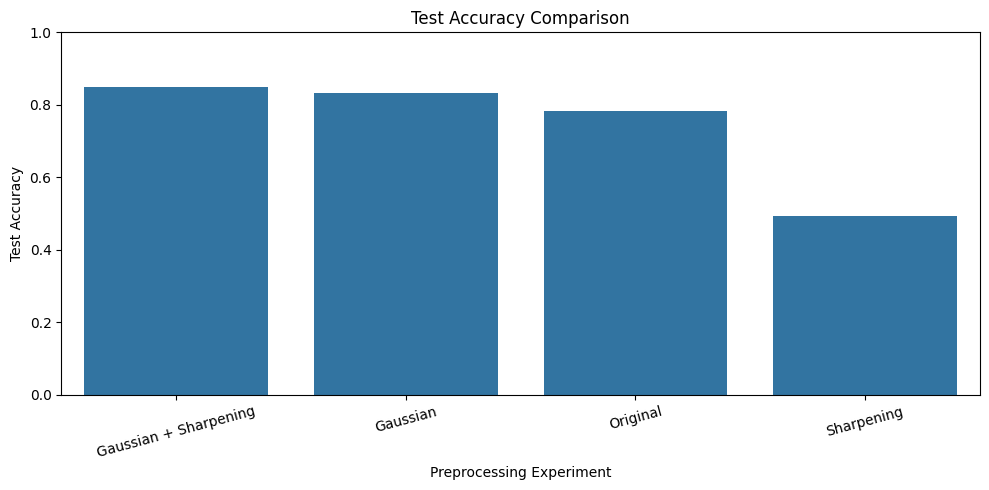

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df,
    x="Experiment",
    y="Test Accuracy"
)
plt.title("Test Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.xlabel("Preprocessing Experiment")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 12. Detailed Evaluation of the Best Experiment

In [13]:
# Select the model using validation accuracy, not test accuracy.
best_experiment = results_df.sort_values(
    by="Best Validation Accuracy",
    ascending=False
).iloc[0]["Experiment"]
best_filter = EXPERIMENTS[best_experiment]
best_model = trained_models[best_experiment]

print("Best experiment:", best_experiment)
print("Filter:", best_filter)

_, _, best_test_dataset = make_experiment_datasets(best_filter)

y_true = np.concatenate([
    labels_batch.numpy()
    for _, labels_batch in best_test_dataset
])

y_prob = best_model.predict(best_test_dataset, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Test Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))


Best experiment: Gaussian + Sharpening
Filter: gaussian_sharpen
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step
Test Accuracy: 0.8481912144702842

Classification Report:
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.91      0.70      0.79       149
                     Pepper__bell___healthy       0.93      0.98      0.95       221
                      Potato___Early_blight       0.87      0.89      0.88       150
                       Potato___Late_blight       0.80      0.71      0.76       150
                           Potato___healthy       0.91      0.43      0.59        23
                      Tomato_Bacterial_spot       0.85      0.96      0.90       319
                        Tomato_Early_blight       0.80      0.52      0.63       150
                         Tomato_Late_blight       0.80      0.79      0.80       287
                           Tomato_Leaf_Mold       0.84      0.74      0.

## 13. Confusion Matrix

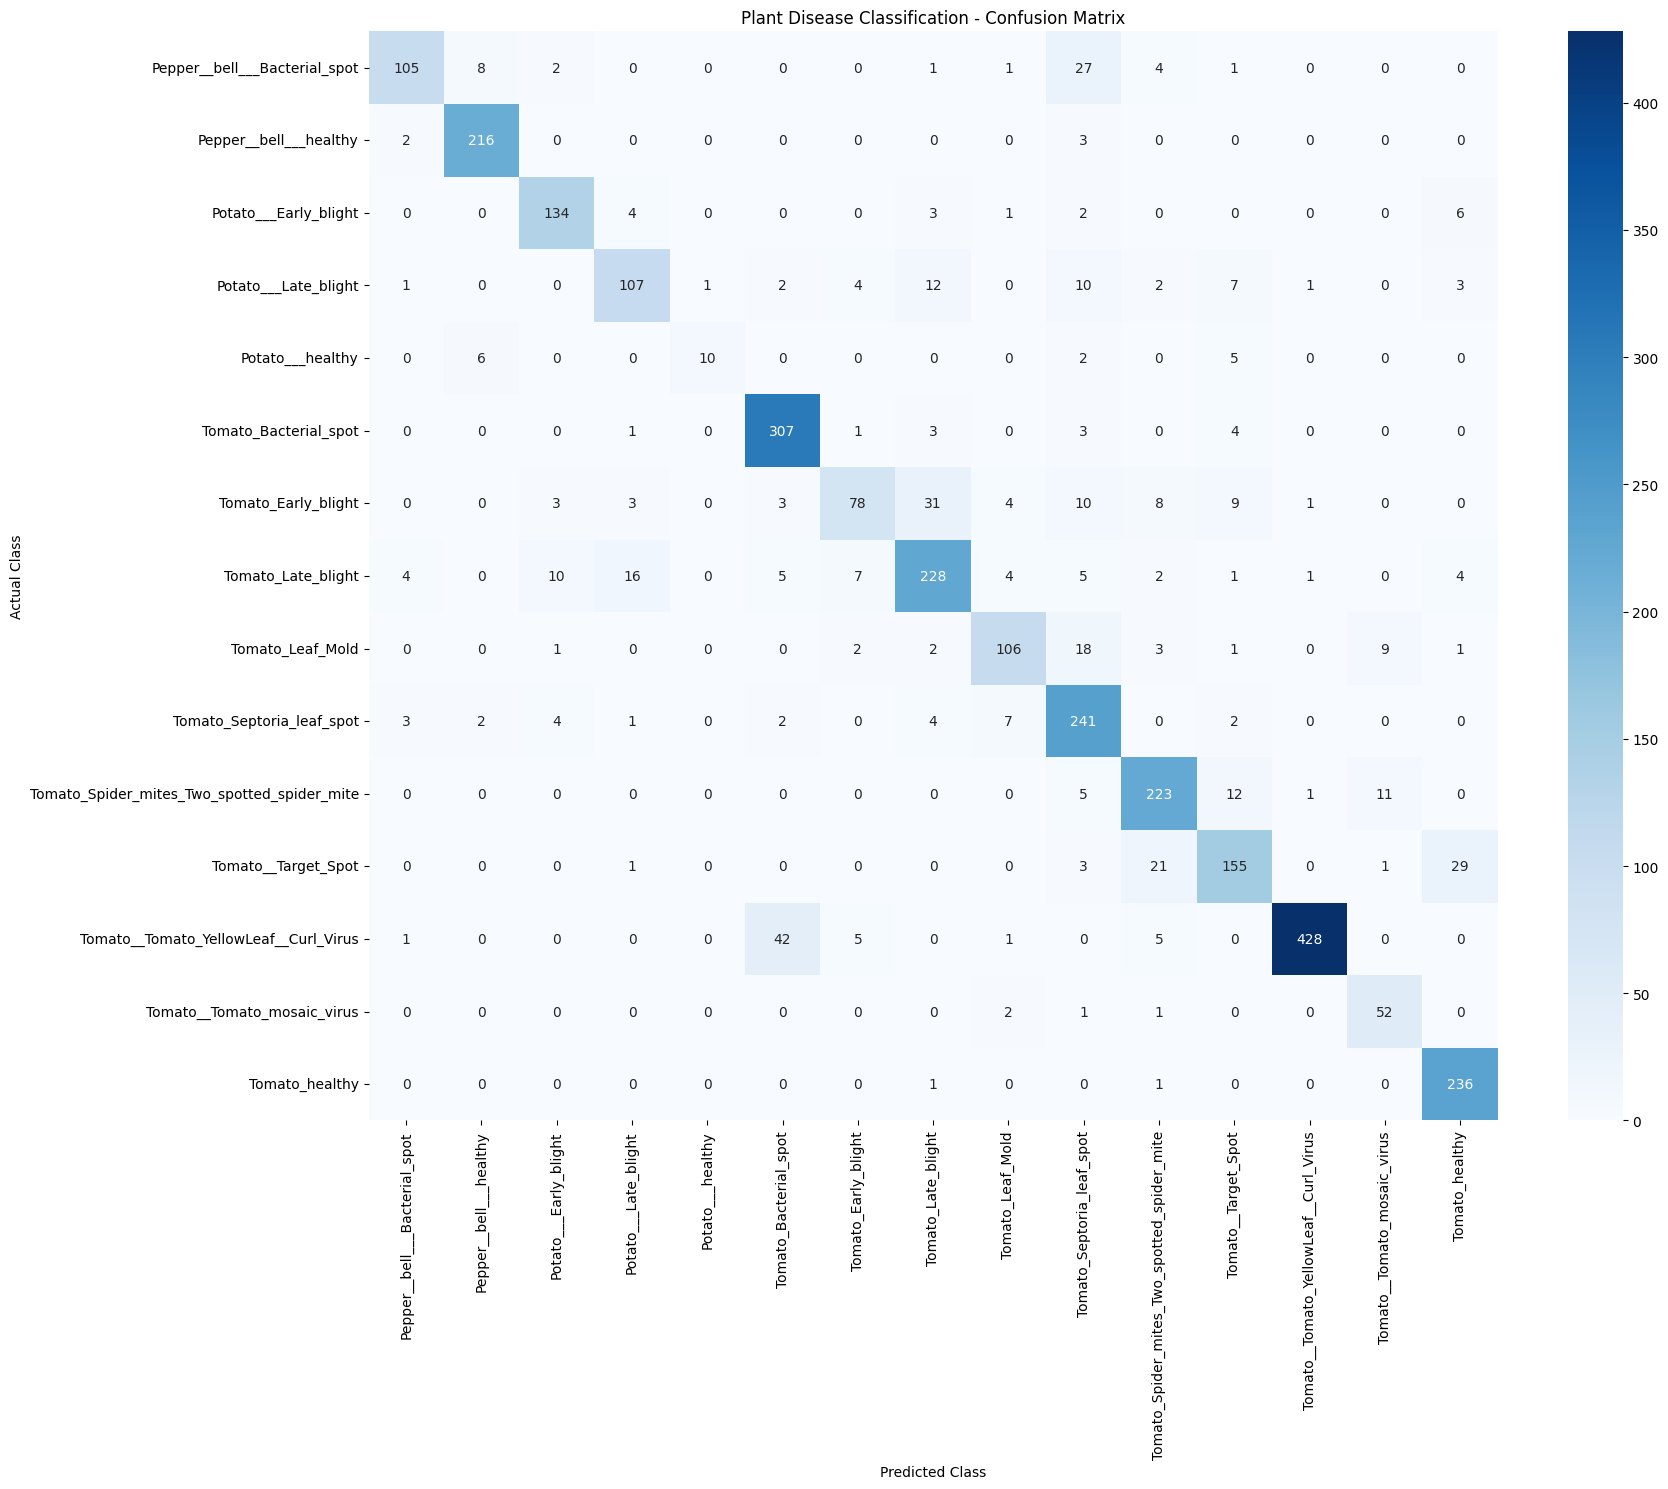

In [14]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Plant Disease Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 14. Plot Training and Validation Accuracy

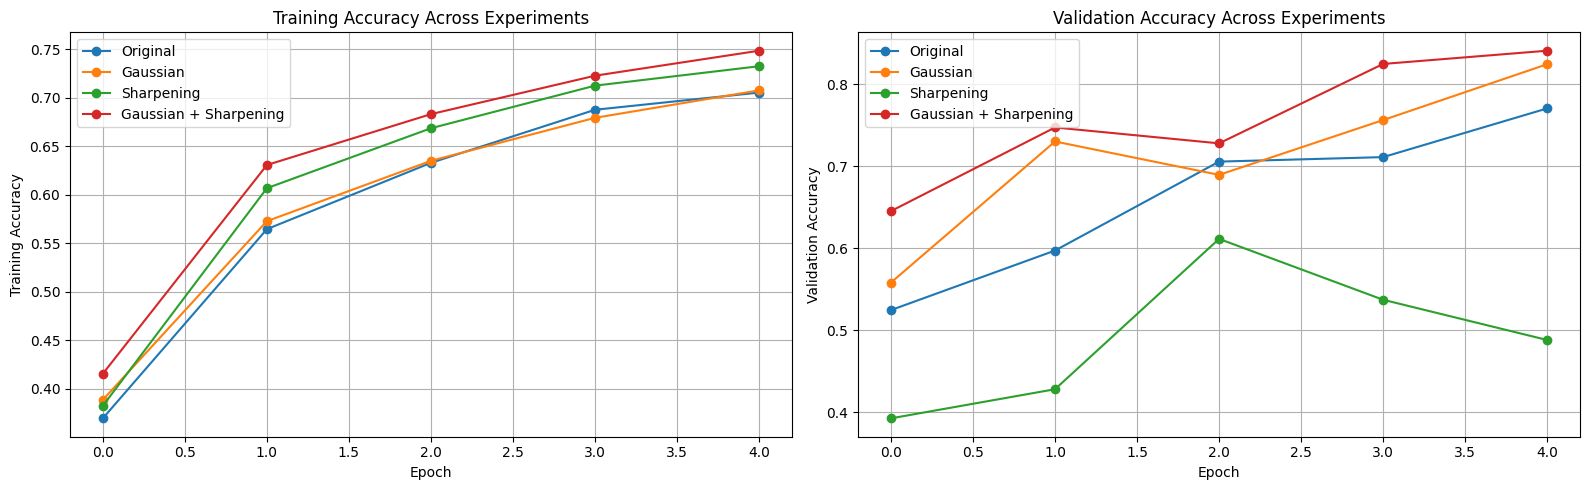

In [16]:
import matplotlib.pyplot as plt

# Plot Training and Validation Accuracy Across Experiments
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for experiment_name, history in histories.items():
   # Training Accuracy
   axes[0].plot(
       history.history["accuracy"],
       marker="o",
       label=experiment_name
   )
   # Validation Accuracy
   axes[1].plot(
       history.history["val_accuracy"],
       marker="o",
       label=experiment_name
   )
axes[0].set_title("Training Accuracy Across Experiments")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Accuracy")
axes[0].legend()
axes[0].grid(True)
axes[1].set_title("Validation Accuracy Across Experiments")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 15. Save the Best Model and Results
The best model is selected using validation accuracy. Test accuracy is reported for comparing the experiments, while the validation set is used to choose the model. This helps avoid selecting a model based on its test-set result.


In [15]:
best_model.save("best_plant_disease_cnn.keras")
results_df.to_csv("filter_experiment_results.csv", index=False)

print("Best model saved as: best_plant_disease_cnn.keras")
print("Experiment results saved as: filter_experiment_results.csv")
print(results_df)


Best model saved as: best_plant_disease_cnn.keras
Experiment results saved as: filter_experiment_results.csv
              Experiment  Best Validation Accuracy  Test Loss  Test Accuracy
0  Gaussian + Sharpening                  0.841085   0.475946       0.848191
1               Gaussian                  0.824612   0.506849       0.833010
2               Original                  0.770672   0.645821       0.783269
3             Sharpening                  0.611434   2.484047       0.492248


## 16. Conclusion
This project investigated the effect of different image filtering techniques on plant disease classification using a Convolutional Neural Network (CNN).
Four experiments were conducted using the same dataset split and CNN architecture:
- **Original Images:** 78.33% test accuracy.
- **Gaussian Smoothing:** 83.30% test accuracy.
- **Sharpening:** 49.22% test accuracy.
- **Gaussian Smoothing + Sharpening:** 84.82% test accuracy.
The combination of Gaussian Smoothing and Sharpening achieved the highest test accuracy of 84.82%, representing an improvement of 6.49 percentage points compared to the original images.
The results demonstrate that image filtering techniques can influence CNN classification performance. Gaussian Smoothing improved the classification accuracy, while Sharpening alone resulted in lower performance than the baseline.
Overall, combining Gaussian Smoothing and Sharpening produced the best classification performance among the four experiments.